# Занятие 2. LLM: RLHF, DPO, PPO и компрессия

**Цель занятия:** получить «мозг» проекта — LLM, адаптированную под предметную область и пригодную для запуска на edge.

- Теория выравнивания: SFT → RM → PPO → DPO → IPO/KTO/ORPO
- SFT с LoRA (loss только по ответу)
- Preference-данные + DPO, win-rate до/после
- PPO/GRPO: почему RL дорого и что используют вместо него
- Компрессия: размер / latency / качество
- Сборка «мозга»: общий интерфейс и реестр реализаций

Модель должна отвечать в формате `Cause: ... Action: ...` — такой ответ легко валидировать и передавать агенту.

**Режимы работы.** `FULL` — есть GPU (Colab T4): модель до 1B, 60 шагов SFT, 4-bit квантование.
`FAST` — CPU: `SmolLM2-135M-Instruct`, 30 шагов SFT, int8. Ячейки одни и те же, поэтому занятие
целиком демонстрируется на CPU, а на T4 те же выводы получаются на большой модели.

**Важно.** Обучение SFT/DPO в этом ноутбуке реализовано **вручную на чистом PyTorch** (без `SFTTrainer`/`DPOTrainer` из TRL):
это убирает зависимость от багов TRL на T4 (`chunked_logprob`/`addmm(bf16->fp32)`). LoRA — через `peft`.


In [ ]:
import os, sys, time, json, gc, warnings, subprocess, copy
from dataclasses import dataclass, field
from abc import ABC, abstractmethod
from typing import Dict, List, Tuple, Type

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings("ignore")
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
try:
    from transformers.utils import logging as hf_logging
    hf_logging.set_verbosity_error()
except Exception:
    pass

IN_COLAB = "COLAB_GPU_TOPOLOGY" in os.environ or os.path.exists("/content")
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
MODE = os.environ.get("COURSE_MODE", "FULL" if DEVICE == "cuda" else "FAST")

if IN_COLAB:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q",
                           "transformers", "datasets", "accelerate", "peft", "bitsandbytes"])

SEED = 42
np.random.seed(SEED); torch.manual_seed(SEED)

@dataclass
class Cfg:
    mode: str = MODE
    device: str = DEVICE
    seed: int = SEED
    model_id: str = field(default="")
    sft_steps: int = field(default=0)
    dpo_steps: int = field(default=0)
    grpo_steps: int = field(default=0)
    dpo_lr: float = field(default=0.0)
    max_len: int = field(default=0)
    def __post_init__(self):
        fast = self.mode == "FAST"
        self.model_id = "HuggingFaceTB/SmolLM2-135M-Instruct" if fast else "Qwen/Qwen2.5-0.5B-Instruct"
        self.sft_steps = 30 if fast else 60
        self.dpo_steps = 10 if fast else 60
        self.grpo_steps = 2 if fast else 20
        self.dpo_lr = 5e-5 if fast else 5e-6
        self.max_len = 64 if fast else 256

CFG = Cfg()
ART = "/home/user/course/artifacts"
os.makedirs(ART, exist_ok=True)
print(f"Режим: {CFG.mode.upper()} | модель: {CFG.model_id} | устройство: {DEVICE}")

Режим: FULL | модель: Qwen/Qwen2.5-0.5B-Instruct | устройство: cuda


## Зачем это и где применяется

**Зачем.** Базовая LLM отвечает «вообще», а не в формате вашей задачи: лишние слова, нет структуры,
нет вашей терминологии. SFT задаёт форму и домен, DPO — предпочтения, которые одной формой не
выразить (тон, полнота, отказ от опасных советов), а компрессия делает модель достаточно лёгкой
для запуска на устройстве.

**Где применяется.** Промышленная диагностика и техподдержка (ответ строго по регламенту),
автоматические отчёты и суммаризация, голосовые помощники на устройстве — везде, где нужен
предсказуемый формат ответа и где облако недоступно или дорого.

## Термины занятия (глоссарий)

| Термин | Смысл |
|---|---|
| **SFT** | Supervised Fine-Tuning: дообучение на парах «запрос → правильный ответ» |
| **Preference-пара** | два ответа на один запрос: `chosen` (лучший) и `rejected` (худший) |
| **Reward Model (RM)** | модель, которая предсказывает оценку человеческого предпочтения для ответа |
| **PPO / GRPO** | RL-алгоритмы, оптимизирующие политику по награде; GRPO оценивает группу сэмплов и обходится без отдельной value-сети |
| **DPO** | Direct Preference Optimization: та же цель, что у RLHF, но без отдельной RM — сразу по preference-парам |
| **`beta`** | сила удержания около исходной модели: больше `beta` — меньше отклоняемся от SFT-модели |
| **Win-rate** | доля примеров, где новая модель лучше базовой по оценке судьи |
| **Margin** | разность оценок `chosen` и `rejected`: растёт — значит DPO действительно учится |
| **Квантование (int8/4-bit)** | веса хранятся в меньшей разрядности: меньше памяти, быстрее, но качество может упасть |
| **Дистилляция** | маленькая модель-ученик учится повторять ответы большой модели-учителя |
| **`merge_and_unload`** | «впечатать» LoRA-адаптер в основные веса и получить обычную модель |


### Архитектура занятия и выбор инструментов

```
базовая LLM ──SFT──▶ ──DPO──▶ ──GRPO──▶ merge_and_unload ──▶ квантование ──▶ LLMBrain
                                                                   │
                                                         замеры: МБ, ток/с, качество
```

| Решение | Пояснение |
|---|---|
| `SmolLM2-135M-Instruct` в `FAST` | instruct-модель уже держит формат ответа, поэтому хватает 30 шагов SFT; в `FULL` — модель до 1B |
| `peft` (LoRA) + ручной цикл | TRL заменён ручным циклом обучения: меньше зависимостей и нет проблем с `chunked_logprob` на T4 |
| DPO без `DPOTrainer` | реализован вручную по формуле `-log σ(β[log π/π_ref chosen − log π/π_ref rejected])` |
| GRPO не запускается | на T4 нестабилен, а для занятия достаточно SFT + DPO |
| Обучение в отдельном процессе | аллокатор PyTorch не возвращает память ОС; воркер даёт чистый замер RSS и гарантированно освобождает память |
| Своя обёртка `Int8Linear` | `torch.quantization.quantize_dynamic` требует fp32-весов, а копия модели во fp32 не влезает в память; обёртка квантует слой за слоем |
| Реестр `BRAIN_REGISTRY` | выбор реализации по строке вместо `if model_name == ...`: новый «мозг» — одна новая строка |


## 1. Теория выравнивания

```
pretraining  ->  SFT  ->  [ Reward Model ]  ->  RL (PPO/GRPO)      # классический RLHF
                   |                              |
                   +--------->  DPO / IPO / KTO / ORPO  <----------+   # прямое выравнивание без RM и RL
```

**RLHF (PPO).** Максимизируем награду, не уходя далеко от исходной политики:
$$\max_{\pi}\ \mathbb{E}_{x,y\sim\pi}\left[r(x,y)\right] - \beta\,\mathrm{KL}\!\left(\pi(\cdot|x)\,\|\,\pi_{ref}(\cdot|x)\right)$$
Цена: в памяти одновременно политика, эталонная модель, reward-модель и value-сеть.

**DPO.** Тот же оптимум без явной reward-модели — через вероятности предпочтений:
$$\mathcal{L}_{DPO} = -\log\sigma\!\left(\beta\left[\log\frac{\pi_\theta(y_w|x)}{\pi_{ref}(y_w|x)} - \log\frac{\pi_\theta(y_l|x)}{\pi_{ref}(y_l|x)}\right]\right)$$

**$\beta$ — главный гиперпараметр:** малое $\beta$ → модель «убегает» за наградой (reward hacking),
большое → почти не отличается от SFT.

In [ ]:
display(pd.DataFrame([
    dict(метод="SFT",        нужна_RM="нет", нужен_RL="нет", данные="(инструкция, ответ)",             стоимость="низкая",  риск="копирует стиль разметчика"),
    dict(метод="RLHF (PPO)", нужна_RM="да",  нужен_RL="да",  данные="предпочтения + RM + value",       стоимость="высокая", риск="reward hacking, нестабильность"),
    dict(метод="GRPO",       нужна_RM="нет", нужен_RL="да",  данные="функция награды / предпочтения",  стоимость="средняя", риск="дорогой rollout, но без value-сети"),
    dict(метод="DPO",        нужна_RM="нет", нужен_RL="нет", данные="пары (chosen, rejected)",         стоимость="низкая",  риск="чувствителен к β и качеству пар"),
    dict(метод="IPO",        нужна_RM="нет", нужен_RL="нет", данные="пары предпочтений",               стоимость="низкая", риск="менее склонен к переобучению, чем DPO"),
    dict(метод="KTO",        нужна_RM="нет", нужен_RL="нет", данные="бинарные «хорошо/плохо»",         стоимость="низкая", риск="нужна калибровка порогов"),
    dict(метод="ORPO",       нужна_RM="нет", нужен_RL="нет", данные="пары предпочтений в SFT-цикле",   стоимость="низкая", риск="смешивает две цели"),
]))
print("Практика 2025–2026: SFT -> DPO для стиля и предпочтений; GRPO — если есть проверяемая функция награды")
print("(тесты, формат, математика). Классический PPO почти вытеснен: дороже и нестабильнее при том же качестве.")

,метод,нужна_RM,нужен_RL,данные,стоимость,риск
0,SFT,нет,нет,"(инструкция, ответ)",низкая,копирует стиль разметчика
1,RLHF (PPO),да,да,предпочтения + RM + value,высокая,"reward hacking, нестабильность"
2,GRPO,нет,да,функция награды / предпочтения,средняя,"дорогой rollout, но без value-сети"
3,DPO,нет,нет,"пары (chosen, rejected)",низкая,чувствителен к β и качеству пар
4,IPO,нет,нет,пары предпочтений,низкая,"менее склонен к переобучению, чем DPO"
5,KTO,нет,нет,бинарные «хорошо/плохо»,низкая,нужна калибровка порогов
6,ORPO,нет,нет,пары предпочтений в SFT-цикле,низкая,смешивает две цели


Практика 2025–2026: SFT -> DPO для стиля и предпочтений; GRPO — если есть проверяемая функция награды
(тесты, формат, математика). Классический PPO почти вытеснен: дороже и нестабильнее при том же качестве.


## 2. Данные: SFT и preference-пары

Учим модель отвечать в формате `Cause: ... Action: ...`. Два важных решения:

1. **loss только по ответу** — в ручном цикле промпт маскируется, чтобы loss считался только по токенам ответа.
2. **LoRA вместо полного файн-тюна** — обучаем <1% параметров, затем сливаем адаптер с весами
   (`merge_and_unload`) перед квантованием.

In [ ]:
FAULTS = [
    ("pump", "vibration", "bearing wear", "replace the bearing"),
    ("compressor", "overheating", "low oil level", "add oil and check the filter"),
    ("conveyor", "belt slipping", "low belt tension", "tighten the belt"),
    ("gearbox", "noise", "lack of lubrication", "check the lubrication level"),
    ("pipeline", "pressure drop", "leak in the loop", "locate and fix the leak"),
    ("fan", "low airflow", "clogged filter", "replace the filter"),
    ("heat exchanger", "temperature rise", "fouled surface", "clean the surface"),
    ("electric motor", "unstable speed", "dirty throttle", "clean the throttle"),
]
TRAIN_FAULTS = FAULTS[:6]
EVAL_FAULTS = FAULTS[6:] + FAULTS[:2]
OOD_QUESTIONS = [
    "The pump makes a strange noise only at night and nobody is around.",
    "The production line stopped suddenly and the operator does not know why.",
]

def chat_prompt(question: str) -> str:
    return f"<|im_start|>user\n{question}<|im_end|>\n<|im_start|>assistant\n"

def question_for(equipment: str, symptom: str) -> str:
    return f"The {equipment} shows {symptom}. Diagnose the fault and propose an action."

def chosen_for(cause: str, action: str) -> str:
    return f"Cause: {cause}. Action: {action}."

VERBOSE = [
    "To diagnose the fault I would need to know more about the operating conditions and the maintenance "
    "history of the equipment, so it is difficult to say anything definite right now.",
    "There are several possible reasons for this behaviour and without a detailed inspection it is not "
    "possible to determine which one applies to your case, I would recommend waiting and observing.",
    "The issue could be related to the power supply, the ambient conditions or the quality of the "
    "installation, so a specialist should inspect the equipment during the next maintenance window.",
]

rng = np.random.default_rng(SEED)
sft_rows, pref_rows = [], []
for eq, sym, cause, action in TRAIN_FAULTS:
    prompt = chat_prompt(question_for(eq, sym))
    chosen = chosen_for(cause, action)
    sft_rows += [{"prompt": prompt, "completion": chosen}] * 20
    for k in range(8):
        if k % 2 == 0:
            j = (FAULTS.index((eq, sym, cause, action)) + 1) % len(FAULTS)
            rejected = chosen_for(FAULTS[j][2], FAULTS[j][3])
        else:
            rejected = VERBOSE[k % len(VERBOSE)]
        pref_rows.append({"prompt": prompt, "chosen": chosen, "rejected": rejected})

rng.shuffle(sft_rows); rng.shuffle(pref_rows)
print(f"SFT: {len(sft_rows)} примеров | preference-пар: {len(pref_rows)}")
print("\nПример preference-пары:")
for k in ("prompt", "chosen", "rejected"):
    print(f"  {k:9s}: {pref_rows[0][k][:140]}")

SFT: 120 примеров | preference-пар: 48

Пример preference-пары:
  prompt   : <|im_start|>user
The gearbox shows noise. Diagnose the fault and propose an action.<|im_end|>
<|im_start|>assistant

  chosen   : Cause: lack of lubrication. Action: check the lubrication level.
  rejected : The issue could be related to the power supply, the ambient conditions or the quality of the installation, so a specialist should inspect th


### 2.1 Отложенная выборка и метрики

* `корректность` — rule-based судья на in-domain промптах (максимум 4 балла: формат + причина + действие);
* `многословие` — доля ответов без структуры «Cause/Action» или длиннее 25 слов (на всех промптах);
* `win_rate_vs_base` — доля примеров, где оценка выше, чем у базовой модели.

В ДЗ допустим и LLM-as-a-judge — но с ручной проверкой ≥10% ответов.

In [ ]:
eval_items = [dict(prompt=chat_prompt(question_for(eq, sym)), cause=cause, action=action, ood=False)
              for eq, sym, cause, action in EVAL_FAULTS]
eval_items += [dict(prompt=chat_prompt(q), cause="", action="", ood=True) for q in OOD_QUESTIONS]
eval_prompts = [it["prompt"] for it in eval_items]

def judge(answer: str, item: Dict) -> float:
    a = answer.lower(); s = 0.0
    if "cause:" in a: s += 1.0
    if "action:" in a: s += 1.0
    if item.get("cause") and item["cause"].split()[0].lower() in a: s += 1.0
    if item.get("action") and item["action"].split()[0].lower() in a: s += 1.0
    s -= 0.03 * max(0, len(answer.split()) - 20)
    return round(s, 3)

def is_verbose(answer: str) -> bool:
    a = answer.lower()
    return ("cause:" not in a) or ("action:" not in a) or (len(answer.split()) > 25)

def scores_of(answers: List[str]) -> List[float]:
    return [judge(a, it) for a, it in zip(answers, eval_items)]

json.dump({"sft": sft_rows, "pref": pref_rows, "prompts": eval_prompts,
           "eval_items": eval_items, "config": CFG.__dict__,
           "model_id": CFG.model_id},
          open(f"{ART}/hw2_data.json", "w"), ensure_ascii=False)
print(f"Данные сохранены для воркера: {ART}/hw2_data.json | промптов в оценке: {len(eval_prompts)}")

Данные сохранены для воркера: /home/user/course/artifacts/hw2_data.json | промптов в оценке: 6


## 3. Обучение: SFT → DPO (ручной цикл на PyTorch)

Скрипт ниже делает полный цикл: базовые ответы → SFT → DPO → слияние адаптера →
замер компрессии. **Обучение написано вручную**: `SFTTrainer`/`DPOTrainer` из TRL не используются,
поэтому проблема `chunked_logprob`/`addmm(bf16->fp32)` на T4 не возникает. LoRA — через `peft`.

In [ ]:
!pip install --upgrade torchao

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 18.9 MB/s  0:00:00
  Attempting uninstall: torchao
    Found existing installation: torchao 0.10.0
    Uninstalling torchao-0.10.0:
      Successfully uninstalled torchao-0.10.0


In [ ]:
# --- Воркер 1: SFT -> DPO ручным циклом на PyTorch, слияние адаптера, сохранение модели
train_worker_code = r'''
import json, sys, os, time, gc, resource, math, random
import numpy as np, torch
import torch.nn.functional as F
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")

data_path, out_path, merged_dir = sys.argv[1:4]
data = json.load(open(data_path, encoding="utf-8"))
cfg = data["config"]; model_id = data["model_id"]; seed = int(cfg["seed"])
torch.manual_seed(seed); np.random.seed(seed); random.seed(seed)

from transformers import AutoTokenizer, AutoModelForCausalLM
from peft import LoraConfig, get_peft_model

DEV = "cuda" if torch.cuda.is_available() else "cpu"

tok = AutoTokenizer.from_pretrained(model_id)
if tok.pad_token is None:
    tok.pad_token = tok.eos_token
model = AutoModelForCausalLM.from_pretrained(model_id).to(DEV)
model.config.pad_token_id = tok.pad_token_id
prompts = data["prompts"]
MAX_LEN = int(cfg["max_len"])

@torch.no_grad()
def gen(mdl, max_new_tokens=30):
    mdl.eval(); out = []
    for p in prompts:
        ids = tok(p, return_tensors="pt").to(mdl.device)
        g = mdl.generate(**ids, max_new_tokens=max_new_tokens, do_sample=False, pad_token_id=tok.pad_token_id)
        out.append(tok.decode(g[0][ids["input_ids"].shape[1]:], skip_special_tokens=True).strip())
    return out

def rss():
    return round(resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1024, 1)

res = {"model_id": model_id, "stages": {}, "rss": {}}
res["stages"]["base"] = {"answers": gen(model)}
res["rss"]["after_base"] = rss()

# ---------- ручной SFT с LoRA: loss только по токенам ответа
lora_cfg = LoraConfig(r=32, lora_alpha=64, target_modules=["q_proj", "v_proj"], task_type="CAUSAL_LM")
model = get_peft_model(model, lora_cfg)
model.print_trainable_parameters()
model.train()

def encode_sft(row):
    p_ids = tok(row["prompt"], add_special_tokens=False).input_ids
    c_ids = tok(row["completion"], add_special_tokens=False).input_ids + [tok.eos_token_id]
    ids = (p_ids + c_ids)[:MAX_LEN]
    labels = ([-100] * len(p_ids) + c_ids)[:MAX_LEN]
    return ids, labels

def collate_sft(batch):
    maxlen = max(len(x[0]) for x in batch)
    ids = torch.full((len(batch), maxlen), tok.pad_token_id, dtype=torch.long)
    lab = torch.full((len(batch), maxlen), -100, dtype=torch.long)
    att = torch.zeros((len(batch), maxlen), dtype=torch.long)
    for i, (x, y) in enumerate(batch):
        ids[i, :len(x)] = torch.tensor(x); lab[i, :len(y)] = torch.tensor(y)
        att[i, :len(x)] = 1
    return ids.to(DEV), lab.to(DEV), att.to(DEV)

sft_data = [encode_sft(r) for r in data["sft"]]
sft_data = [d for d in sft_data if any(t != -100 for t in d[1])]
opt = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=1e-3)
BS = 4
t0 = time.time(); step = 0
while step < int(cfg["sft_steps"]):
    random.shuffle(sft_data)
    for i in range(0, len(sft_data), BS):
        batch = sft_data[i:i+BS]
        ids, lab, att = collate_sft(batch)
        out = model(input_ids=ids, attention_mask=att, labels=lab)
        loss = out.loss
        opt.zero_grad(); loss.backward(); opt.step()
        step += 1
        if step % max(1, int(cfg["sft_steps"]) // 3) == 0:
            print(f"SFT step {step}: loss={loss.item():.4f}")
        if step >= int(cfg["sft_steps"]):
            break
res["sft_time_s"] = round(time.time() - t0, 1)
res["stages"]["SFT"] = {"answers": gen(model)}
res["rss"]["after_sft"] = rss()

# ---------- ручной DPO
# ref_model=None: используем саму SFT-модель с отключёнными LoRA-адаптерами как reference.
def encode_pair(row):
    p_ids = tok(row["prompt"], add_special_tokens=False).input_ids
    def enc(resp):
        r_ids = tok(resp, add_special_tokens=False).input_ids + [tok.eos_token_id]
        ids = (p_ids + r_ids)[:MAX_LEN]
        return ids, len(p_ids), len(ids) - len(p_ids)
    return enc(row["chosen"]), enc(row["rejected"])

def collate_dpo(batch):
    out = {}
    for key, idx in (("chosen", 0), ("rejected", 1)):
        maxlen = max(len(x[idx][0]) for x in batch)
        ids = torch.full((len(batch), maxlen), tok.pad_token_id, dtype=torch.long)
        att = torch.zeros((len(batch), maxlen), dtype=torch.long)
        starts = []; lens = []
        for i, x in enumerate(batch):
            seq, s, l = x[idx]
            ids[i, :len(seq)] = torch.tensor(seq); att[i, :len(seq)] = 1
            starts.append(s); lens.append(l)
        out[key] = (ids.to(DEV), att.to(DEV), torch.tensor(starts, device=DEV), torch.tensor(lens, device=DEV))
    return out

def seq_logprob(mdl, ids, att, starts, lens):
    """Суммарный log-prob только по токенам ответа (loss по ответу, а не по промпту)."""
    out = mdl(input_ids=ids, attention_mask=att)
    logp = F.log_softmax(out.logits.float(), dim=-1)
    total = torch.zeros(ids.size(0), device=ids.device)
    for i in range(ids.size(0)):
        s = int(starts[i]); L = int(lens[i])
        if L <= 0:
            continue
        tgt = ids[i, s:s+L]                       # токены ответа
        lp = logp[i, s-1:s-1+L].gather(-1, tgt.unsqueeze(-1)).squeeze(-1)
        total[i] = lp.sum()
    return total

def set_lora_enabled(enabled: bool):
    for n, m in model.named_modules():
        if "lora" in n.lower() and hasattr(m, "weight"):
            m.weight.requires_grad = enabled

dpo_data = [encode_pair(r) for r in data["pref"]]
dpo_data = [d for d in dpo_data if d[0][2] > 0 and d[1][2] > 0]
opt = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=float(cfg["dpo_lr"]))
BETA = 0.1
BS = 2
margins_hist, accs_hist = [], []
t0 = time.time(); step = 0
model.train()
while step < int(cfg["dpo_steps"]):
    random.shuffle(dpo_data)
    for i in range(0, len(dpo_data), BS):
        batch = dpo_data[i:i+BS]
        if not batch:
            continue
        col = collate_dpo(batch)

        # policy log-prob
        lw = seq_logprob(model, *col["chosen"])
        ll = seq_logprob(model, *col["rejected"])

        # reference log-prob: те же веса с выключенным LoRA-адаптером
        with torch.no_grad():
            with model.disable_adapter():
                rw = seq_logprob(model, *col["chosen"])
                rl = seq_logprob(model, *col["rejected"])

        logits = BETA * ((lw - rw) - (ll - rl))
        loss = -F.logsigmoid(logits).mean()

        opt.zero_grad(); loss.backward(); opt.step()
        step += 1

        with torch.no_grad():
            margin = ((lw - rw) - (ll - rl)).mean().item()
            acc = (logits > 0).float().mean().item()
        margins_hist.append(margin); accs_hist.append(acc)
        if step % max(1, int(cfg["dpo_steps"]) // 3) == 0:
            print(f"DPO step {step}: loss={loss.item():.4f} margin={margin:.4f} acc={acc:.3f}")
        if step >= int(cfg["dpo_steps"]):
            break
res["dpo_time_s"] = round(time.time() - t0, 1)
res["dpo_margins"] = [round(m, 5) for m in margins_hist]
res["dpo_accs"] = [round(a, 3) for a in accs_hist]
res["stages"]["SFT+DPO"] = {"answers": gen(model)}
res["rss"]["after_dpo"] = rss()

# Заглушки для совместимости с последующими ячейками (GRPO не запускаем)
res["grpo_time_s"] = 0
res["stages"]["SFT+DPO+GRPO"] = res["stages"]["SFT+DPO"]
res["rss"]["after_grpo"] = res["rss"]["after_dpo"]

# ---------- слияние LoRA и сохранение
merged = model.merge_and_unload()
merged.eval()
merged.save_pretrained(merged_dir); tok.save_pretrained(merged_dir)
res["peak_rss_mb"] = rss()
json.dump(res, open(out_path, "w"), ensure_ascii=False, indent=1)
print("train_worker: готово; пик RSS", res["peak_rss_mb"], "МБ")
'''

# --- Воркер 2: замер компрессии (отдельный процесс — чистое измерение памяти)
compress_worker_code = r'''
import json, sys, os, time, gc, resource
import torch, torch.nn as nn
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")

merged_dir, prompts_json, out_path, quant_path = sys.argv[1:5]
prompts = json.load(open(prompts_json, encoding="utf-8"))
from transformers import AutoTokenizer, AutoModelForCausalLM

tok = AutoTokenizer.from_pretrained(merged_dir)
if tok.pad_token is None:
    tok.pad_token = tok.eos_token

class Int8Linear(nn.Module):
    def __init__(self, linear):
        super().__init__()
        from torch.ao.nn.quantized.dynamic import Linear as QLinear
        from torch.ao.quantization import default_dynamic_qconfig
        c = nn.Linear(linear.in_features, linear.out_features, bias=linear.bias is not None)
        with torch.no_grad():
            c.weight.copy_(linear.weight.float())
            if linear.bias is not None:
                c.bias.copy_(linear.bias.float())
        c.qconfig = default_dynamic_qconfig
        self.q = QLinear.from_float(c)
    def forward(self, x):
        return self.q(x.float()).to(x.dtype)

def quantize_weights_int8(model):
    n = 0
    for parent in [model] + list(model.modules()):
        for name, child in list(parent.named_children()):
            if isinstance(child, nn.Linear):
                setattr(parent, name, Int8Linear(child))
                n += 1
    return n

def param_mb(model):
    total = 0
    for mod in model.modules():
        if isinstance(mod, Int8Linear):
            w, b = mod.q._weight_bias()
            total += w.numel() * 1
            if b is not None:
                total += b.numel() * b.element_size()
        else:
            for p in mod.parameters(recurse=False):
                total += p.numel() * p.element_size()
    return total / (1024 ** 2)

@torch.no_grad()
def gen(mdl, max_new_tokens=30):
    mdl.eval(); out = []
    for p in prompts:
        ids = tok(p, return_tensors="pt").to(mdl.device)
        g = mdl.generate(**ids, max_new_tokens=max_new_tokens, do_sample=False, pad_token_id=tok.pad_token_id)
        out.append(tok.decode(g[0][ids["input_ids"].shape[1]:], skip_special_tokens=True).strip())
    return out

@torch.no_grad()
def latency(mdl, max_new_tokens=24, repeats=2):
    mdl.eval(); t0 = time.time(); n = 0
    for _ in range(repeats):
        for p in prompts[:4]:
            ids = tok(p, return_tensors="pt").to(mdl.device)
            g = mdl.generate(**ids, max_new_tokens=max_new_tokens, do_sample=False, pad_token_id=tok.pad_token_id)
            n += g.shape[1] - ids["input_ids"].shape[1]
    dt = time.time() - t0
    return n / dt if dt > 0 else 0.0

res = {}
dense = AutoModelForCausalLM.from_pretrained(merged_dir)
res["dense_dtype"] = str(next(dense.parameters()).dtype).replace("torch.", "")
res["dense_size_mb"] = round(param_mb(dense), 1)
res["dense_tok_s"] = round(latency(dense), 1)
res["dense_answers"] = gen(dense)
del dense; gc.collect()

qmodel = AutoModelForCausalLM.from_pretrained(merged_dir)
res["quantized_layers"] = quantize_weights_int8(qmodel)
res["quant_size_mb"] = round(param_mb(qmodel), 1)
res["quant_tok_s"] = round(latency(qmodel), 1)
res["quant_answers"] = gen(qmodel)
torch.save(qmodel, quant_path)
res["peak_rss_mb"] = round(resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1024, 1)
json.dump(res, open(out_path, "w"), ensure_ascii=False, indent=1)
print("compress_worker: готово; пик RSS", res["peak_rss_mb"], "МБ")
'''

train_worker_path = f"{ART}/train_worker.py"
compress_worker_path = f"{ART}/compress_worker.py"
out_path = f"{ART}/hw2_results.json"
merged_dir = f"{ART}/merged_model"
quant_path = f"{ART}/quantized_model.pt"
prompts_path = f"{ART}/eval_prompts.json"
json.dump(eval_prompts, open(prompts_path, "w"), ensure_ascii=False)
open(train_worker_path, "w").write(train_worker_code)
open(compress_worker_path, "w").write(compress_worker_code)

WORKER_ENV = {**os.environ, "MALLOC_ARENA_MAX": "1"}

t0 = time.time()
proc = subprocess.run(
    [sys.executable, train_worker_path, f"{ART}/hw2_data.json", out_path, merged_dir],
    env=WORKER_ENV, capture_output=True, text=True
)
if proc.returncode != 0:
    print("=== train_worker STDOUT ===")
    print(proc.stdout[-3000:] if proc.stdout else "(empty)")
    print("=== train_worker STDERR ===")
    print(proc.stderr[-4000:] if proc.stderr else "(empty)")
    raise RuntimeError(f"train_worker failed with code {proc.returncode}")
print(proc.stdout[-2000:] if proc.stdout else "(no stdout)")
R = json.load(open(out_path, encoding="utf-8"))
print(f"Обучение завершено за {time.time()-t0:.0f} с | пик RSS воркера: {R['peak_rss_mb']:.0f} МБ")

t0 = time.time()
proc2 = subprocess.run(
    [sys.executable, compress_worker_path, merged_dir, prompts_path,
     f"{ART}/hw2_compression.json", quant_path],
    env=WORKER_ENV, capture_output=True, text=True
)
if proc2.returncode != 0:
    print("=== compress_worker STDERR ===")
    print(proc2.stderr[-4000:] if proc2.stderr else "(empty)")
    raise RuntimeError(f"compress_worker failed with code {proc2.returncode}")
R.update(json.load(open(f"{ART}/hw2_compression.json", encoding="utf-8")))
print(f"Замер компрессии выполнен за {time.time()-t0:.0f} с | пик RSS воркера: {R['peak_rss_mb']:.0f} МБ")

trainable params: 2,162,688 || all params: 496,195,456 || trainable%: 0.4359
SFT step 20: loss=0.0091
SFT step 40: loss=0.0004
SFT step 60: loss=0.0002
DPO step 20: loss=0.0904 margin=23.6490 acc=1.000
DPO step 40: loss=0.0000 margin=166.3867 acc=1.000
DPO step 60: loss=0.0299 margin=110.4711 acc=1.000
train_worker: готово; пик RSS 2702.9 МБ

Обучение завершено за 94 с | пик RSS воркера: 2703 МБ
Замер компрессии выполнен за 90 с | пик RSS воркера: 2914 МБ


### 3.1 Результаты по стадиям

In [ ]:
base_scores = scores_of(R["stages"]["base"]["answers"])
in_domain = [i for i, it in enumerate(eval_items) if not it["ood"]]
rows = []
for name, payload in R["stages"].items():
    answers = payload["answers"]
    sc = scores_of(answers)
    rows.append(dict(стадия=name,
                     корректность=round(float(np.mean([sc[i] for i in in_domain])), 3),
                     многословие=round(float(np.mean([is_verbose(a) for a in answers])), 3),
                     win_rate_vs_base=round(float(np.mean([s > b for s, b in zip(sc, base_scores)])), 3),
                     слов_в_ответе=round(float(np.mean([len(a.split()) for a in answers])), 1)))
df_stages = pd.DataFrame(rows)
display(df_stages)
display(pd.DataFrame([dict(этап="SFT", шагов=CFG.sft_steps, время_с=R["sft_time_s"]),
                      dict(этап="DPO", шагов=CFG.dpo_steps, время_с=R["dpo_time_s"]),
                      dict(этап="GRPO", шагов=CFG.grpo_steps, время_с=R["grpo_time_s"])]))

print("Примеры (база -> SFT -> SFT+DPO):")
for i in range(min(3, len(eval_prompts))):
    print(f"\n  [{i}] base : {R['stages']['base']['answers'][i][:100]}")
    print(f"      SFT  : {R['stages']['SFT']['answers'][i][:100]}")
    print(f"      DPO  : {R['stages']['SFT+DPO']['answers'][i][:100]}")

,стадия,корректность,многословие,win_rate_vs_base,слов_в_ответе
0,base,0.388,1.000,0.0,25.0
1,SFT,3.000,0.333,1.0,7.5
2,SFT+DPO,3.000,0.333,1.0,7.0
3,SFT+DPO+GRPO,3.000,0.333,1.0,7.0


,этап,шагов,время_с
0,SFT,60,11.6
1,DPO,60,25.7
2,GRPO,20,0.0


Примеры (база -> SFT -> SFT+DPO):

  [0] base : Based on the information provided, it is difficult to determine the exact cause of the temperature r
      SFT  : Cause: low oil level. Action: add oil and check the filter.
      DPO  : Cause: low temperature. Action: check the fuel level.

  [1] base : To diagnose and address the issue of an unstable speed in an electric motor, you can follow these st
      SFT  : Cause: low speed. Action: check the lubrication level.
      DPO  : Cause: low speed. Action: check the lubrication level.

  [2] base : To diagnose the fault in a pump that is showing vibration, you should follow these steps:

1. **Iden
      SFT  : Cause: bearing wear. Action: replace the bearing.
      DPO  : Cause: bearing wear. Action: replace the bearing.


### 3.2 Обучается ли сама целевая функция DPO?

Даже когда внешняя метрика на потолке, DPO обязан увеличивать «зазор» наград между `chosen` и `rejected`.
Если зазор не растёт — проблема в данных или в learning rate, а не в «неэффективности DPO».

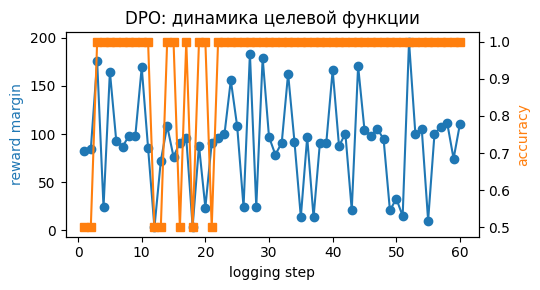

reward margin: 82.15404 -> 110.47112


In [ ]:
margins, accs = R["dpo_margins"], R["dpo_accs"]
fig, ax1 = plt.subplots(figsize=(5.5, 3))
ax1.plot(range(1, len(margins) + 1), margins, marker="o", color="tab:blue", label="reward margin")
ax1.set_xlabel("logging step"); ax1.set_ylabel("reward margin", color="tab:blue")
ax2 = ax1.twinx()
ax2.plot(range(1, len(accs) + 1), accs, marker="s", color="tab:orange", label="preference accuracy")
ax2.set_ylabel("accuracy", color="tab:orange")
plt.title("DPO: динамика целевой функции"); fig.tight_layout(); plt.show()
print(f"reward margin: {margins[0]} -> {margins[-1]}")

## 4. Компрессия: размер, latency, качество

In [ ]:
# сравниваем dense и int8 на одних и тех же промптах и с одним и тем же судьёй
score_dense = float(np.mean(scores_of(R["dense_answers"])))
score_quant = float(np.mean(scores_of(R["quant_answers"])))
df_compress = pd.DataFrame([
    dict(вариант=f"dense {R['dense_dtype']}", размер_МБ=R["dense_size_mb"], токенов_с=R["dense_tok_s"],
         оценка=round(score_dense, 3)),
    dict(вариант="int8 dynamic", размер_МБ=R["quant_size_mb"], токенов_с=R["quant_tok_s"],
         оценка=round(score_quant, 3)),
])
df_compress["сжатие_размера_×"] = (df_compress["размер_МБ"].max() / df_compress["размер_МБ"]).round(2)
df_compress["деградация_качества"] = (df_compress["оценка"].max() - df_compress["оценка"]).round(3)
display(df_compress)
print(f"Квантовано Linear-слоёв: {R['quantized_layers']}")
print("\nПримеры ответов:")
for i in range(min(3, len(eval_prompts))):
    print(f"  dense: {R['dense_answers'][i][:90]}")
    print(f"  int8 : {R['quant_answers'][i][:90]}")

,вариант,размер_МБ,токенов_с,оценка,сжатие_размера_×,деградация_качества
0,dense bfloat16,1201.9,4.6,2.333,1.00,0.000
1,int8 dynamic,730.9,10.8,2.000,1.64,0.333


Квантовано Linear-слоёв: 169

Примеры ответов:
  dense: Cause: low temperature. Action: check the fuel level.
  int8 : Cause: lack of dike. Action: check the dike.
  dense: Cause: low speed. Action: check the lubrication level.
  int8 : Cause: lack of maintenance. Action: repair the leak. Cause: failure of the lubrication sys
  dense: Cause: bearing wear. Action: replace the bearing.
  int8 : Cause: lack of self-vibration. Action: check the bearing.


### 4.1 Дистилляция (мини-пример)

Учитель (большая сеть) → ученик (маленькая): ученик повторяет «мягкие» логиты учителя.

In [ ]:
torch.manual_seed(0)
teacher = nn.Sequential(nn.Linear(32, 128), nn.Tanh(), nn.Linear(128, 8))
student = nn.Sequential(nn.Linear(32, 32), nn.Tanh(), nn.Linear(32, 8))
X = torch.randn(512, 32)
with torch.no_grad():
    y = teacher(X).argmax(1)
    soft = teacher(X)

def fit(model, mode, epochs=150):
    opt = torch.optim.Adam(model.parameters(), lr=5e-3)
    for _ in range(epochs):
        opt.zero_grad()
        if mode == "distill":
            loss = 0.5 * nn.MSELoss()(model(X), soft) + 0.5 * nn.CrossEntropyLoss()(model(X), y)
        else:
            loss = nn.CrossEntropyLoss()(model(X), y)
        loss.backward(); opt.step()
    return float((model(X).argmax(1) == y).float().mean())

acc_hard, acc_distill = fit(copy.deepcopy(student), "hard"), fit(copy.deepcopy(student), "distill")
print(f"Ученик без дистилляции: {acc_hard:.3f} | с дистилляцией: {acc_distill:.3f} "
      f"| параметров ученика: {sum(p.numel() for p in student.parameters())}")

Ученик без дистилляции: 1.000 | с дистилляцией: 0.990 | параметров ученика: 1320


## 5. Сборка «мозга»: интерфейс `LLMBrain`

Здесь нужен абстрактный класс —
у нас есть **две реализации одного контракта** (полновесная и квантованная), и оркестратор должен уметь брать любую. Для одного класса абстракция не нужна —
достаточно обычного класса или функции.

Контракт совместим с модулем восприятия из занятия 1: оркестратор вызывает
`decide(context)` и `explain(context)` и не знает, какая реализация внутри.

In [ ]:
class LLMBrain(ABC):
    """Контракт «мозга» системы. Совместим с MultimodalPerception из занятия 1."""
    @abstractmethod
    def decide(self, context: Dict) -> str: ...
    @abstractmethod
    def explain(self, context: Dict) -> str: ...

class HFBrain(LLMBrain):
    """Базовая реализация поверх HF-модели: decide() = генерация по промпту из контекста."""
    kind = "hf"
    def __init__(self, model, tokenizer, max_new_tokens: int = 24):
        self.model, self.tok, self.max_new_tokens = model, tokenizer, max_new_tokens
    def build_prompt(self, context: Dict) -> str:
        return context.get("prompt") or chat_prompt(
            question_for(context.get("object", "pump"), context.get("symptom", "vibration")))
    def decide(self, context: Dict) -> str:
        ids = self.tok(self.build_prompt(context), return_tensors="pt").to(self.model.device)
        with torch.no_grad():
            g = self.model.generate(**ids, max_new_tokens=self.max_new_tokens, do_sample=False,
                                    pad_token_id=self.tok.pad_token_id)
        return self.tok.decode(g[0][ids["input_ids"].shape[1]:], skip_special_tokens=True).strip()
    def explain(self, context: Dict) -> str:
        return f"[{self.kind}] {sum(p.numel() for p in self.model.parameters())/1e6:.0f}M параметров"

class DenseBrain(HFBrain):
    """Полновесная модель: максимальное качество, максимальная цена памяти."""
    kind = "dense"
    def explain(self, context: Dict) -> str:
        return f"[dense] качество максимально, памяти {param_mb(self.model):.0f} МБ"

class QuantizedBrain(HFBrain):
    """Та же модель в int8: дешевле по памяти, качество — по замеру выше."""
    kind = "quantized"
    def explain(self, context: Dict) -> str:
        return f"[int8] памяти {param_mb(self.model):.0f} МБ, качество по замеру"

# Реестр реализаций: новый «мозг» = новая строка, оркестратор не меняется
BRAIN_REGISTRY: Dict[str, Type[LLMBrain]] = {"dense": DenseBrain, "quantized": QuantizedBrain}

def param_mb(model) -> float:
    """Честный размер весов: упакованные int8-веса не видны в parameters(), считаем их отдельно."""
    total = 0
    for mod in model.modules():
        if hasattr(mod, "q") and hasattr(mod.q, "_weight_bias"):      # Int8Linear
            w, b = mod.q._weight_bias()
            total += w.numel() * 1
            if b is not None:
                total += b.numel() * b.element_size()
        else:
            for p in mod.parameters(recurse=False):
                total += p.numel() * p.element_size()
    return total / (1024 ** 2)

def build_brain(kind: str, model, tokenizer, **kwargs) -> LLMBrain:
    """Единственная точка выбора реализации."""
    if kind not in BRAIN_REGISTRY:
        raise KeyError(f"неизвестный мозг: {kind}. Доступны: {list(BRAIN_REGISTRY)}")
    return BRAIN_REGISTRY[kind](model, tokenizer, **kwargs)

In [ ]:
from transformers import AutoTokenizer, AutoModelForCausalLM

class Int8Linear(nn.Module):
    """Веса Linear в int8, активации — в исходном dtype. Класс повторяет определение из воркера:
    он нужен, чтобы корректно загрузить сохранённую квантованную модель (pickle ищет класс в __main__)."""
    def __init__(self, linear=None, q=None):
        # linear=None, q готовое — вариант для загрузки из файла; иначе квантуем переданный слой
        super().__init__()
        if q is not None:
            self.q = q
        else:
            from torch.ao.nn.quantized.dynamic import Linear as QLinear
            from torch.ao.quantization import default_dynamic_qconfig
            c = nn.Linear(linear.in_features, linear.out_features, bias=linear.bias is not None)
            with torch.no_grad():
                c.weight.copy_(linear.weight.float())
                if linear.bias is not None:
                    c.bias.copy_(linear.bias.float())
            c.qconfig = default_dynamic_qconfig
            self.q = QLinear.from_float(c)
    def forward(self, x):
        # активации считаем во float и возвращаем в исходный dtype модели
        return self.q(x.float()).to(x.dtype)

tok = AutoTokenizer.from_pretrained(merged_dir)
if tok.pad_token is None:
    tok.pad_token = tok.eos_token

scenarios = [dict(object=eq, symptom=sym, prompt=chat_prompt(question_for(eq, sym)))
             for eq, sym, _, _ in EVAL_FAULTS[:4]]

results_brains = []
dense_model = AutoModelForCausalLM.from_pretrained(merged_dir)         # dense — с диска
brain = build_brain("dense", dense_model, tok)
t0 = time.time(); ans = [brain.decide(s) for s in scenarios]; t_dense = (time.time() - t0) / len(scenarios)
results_brains.append(dict(мозг="dense", пример=ans[0][:60], среднее_время_с=round(t_dense, 2),
                           пояснение=brain.explain(scenarios[0])))
del dense_model, brain; gc.collect()

quant_model = torch.load(quant_path, map_location="cpu", weights_only=False)   # сохранена воркером
brain = build_brain("quantized", quant_model, tok)
t0 = time.time(); ans = [brain.decide(s) for s in scenarios]; t_quant = (time.time() - t0) / len(scenarios)
results_brains.append(dict(мозг="quantized", пример=ans[0][:60], среднее_время_с=round(t_quant, 2),
                           пояснение=brain.explain(scenarios[0])))
del quant_model, brain; gc.collect()

display(pd.DataFrame(results_brains))
print("Обе реализации взаимозаменяемы в оркестраторе (занятие 3): он вызывает decide/explain и не знает, какая именно стоит за ключом реестра.")

W1114 15:09:14.295000 570 torch/utils/_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
W1114 15:09:14.344000 570 torch/utils/_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

,мозг,пример,среднее_время_с,пояснение
0,dense,Cause: low temperature. Action: check the fuel...,3.50,"[dense] качество максимально, памяти 1202 МБ"
1,quantized,Cause: lack of dike. Action: check the dike.,2.69,"[int8] памяти 731 МБ, качество по замеру"


Обе реализации взаимозаменяемы в оркестраторе (занятие 3): он вызывает decide/explain и не знает, какая именно стоит за ключом реестра.


In [ ]:
import resource
artifacts = {
    "mode": CFG.mode, "model": CFG.model_id, "device": DEVICE,
    "stages": df_stages.to_dict("records"),
    "compression": df_compress.to_dict("records"),
    "dpo": {"margins": margins, "accuracies": accs, "lr": CFG.dpo_lr, "beta": 0.1},
    "timing_s": {"sft": R["sft_time_s"], "dpo": R["dpo_time_s"], "grpo": R["grpo_time_s"]},
    "distillation": {"hard_acc": round(acc_hard, 3), "distill_acc": round(acc_distill, 3)},
    "worker_peak_rss_mb": R["peak_rss_mb"],
    "notebook_peak_rss_mb": round(resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1024, 1),
}
json.dump(artifacts, open(f"{ART}/hw2_metrics.json", "w"), ensure_ascii=False, indent=1)
print("Сохранено:", f"{ART}/hw2_metrics.json")
print(f"Пик памяти: воркер {artifacts['worker_peak_rss_mb']} МБ | ноутбук {artifacts['notebook_peak_rss_mb']} МБ")

Сохранено: /home/user/course/artifacts/hw2_metrics.json
Пик памяти: воркер 2913.6 МБ | ноутбук 2364.9 МБ


## 6. Упражнения для самостоятельной работы (в ноутбуке)

1. Измените `beta` DPO (0.05 / 0.1 / 0.5) и постройте график «корректность и маржа от beta».
2. Сравните `learning_rate` DPO: 1e-5 / 5e-5 / 5e-4 — где начинается деградация?
3. Замените rule-based судью на LLM-as-a-judge (в FULL-режиме) и сравните корреляцию оценок.
4. Добавьте в `BRAIN_REGISTRY` третий мозг — `distilled`, и убедитесь, что оркестратор не меняется.
5. Измерьте latency при батче 1 / 4 / 8 и объясните результат для int8.

---
# Домашнее задание 2. Выравнивание и компрессия LLM

**Цель:** получить «мозг» проекта — модель, адаптированную под предметную область и пригодную для edge.

### Что сделать

1. **Доменный preference-датасет** ≥20 пар `chosen/rejected`. Источники: ручная разметка,
   синтетика через сильную модель, шаблоны с типичными ошибками. `rejected` — правдоподобный, но худший.
2. **SFT** базовой модели (≤1B параметров) через LoRA, с loss только по ответу.
3. **DPO** на своём датасете. Сравнить **base / SFT / SFT+DPO** по win-rate на 10 отложенных примерах
   (судья — человек или сильная модель + ручная проверка ≥10%).
4. **Компрессия:** квантовать лучшую модель в int8; замерить
   размер до/после, latency (ток/с), деградацию качества.
5. **Обёртка `LLMBrain`** (общий интерфейс с методами `decide`, `explain`, выбор через реестр).
   Продемонстрировать на 2 сценариях.
6. **Отчёт:** таблица + 2–3 вывода + рекомендация, какую конфигурацию брать в проект.

### Формат сдачи

* `hw2_<группа>.ipynb` (исполненный) + `hw2_report.md`;
* все три стадии обучены и сравнены на одной отложенной выборке; замеры latency — с указанием платформы.

### Технические условия

* GPU не требуется. На CPU берите модель ≤0.5B (например, `HuggingFaceTB/SmolLM2-135M-Instruct`),
  ≤50 шагов SFT и ≤15 шагов DPO — этого хватает, чтобы увидеть разницу между стадиями.
* 4-bit квантование (bitsandbytes) требует GPU и **не обязательно**; int8 делается на CPU.

### Критерии оценки (максимум 10 баллов)

| Критерий | Баллы | Что проверяется |
|---|---|---|
| Preference-датасет | 2 | ≥20 пар, `rejected` содержательный, описан способ разметки |
| SFT | 2 | LoRA-SFT обучен, loss только по ответу, кривая loss приведена |
| DPO + сравнение 3 стадий | 3 | DPO обучен; win-rate/оценка для base / SFT / SFT+DPO на одной выборке |
| Компрессия | 2 | Размер, latency, деградация качества — все три числа, указана платформа |
| Интерфейс `LLMBrain` | 1 | Общий интерфейс + реестр (без `if model_name == ...`), 2 сценария |
